# S&P 500 (GSPC) 日足

In [1]:
import sys

path_up = ".."
if not path_up in sys.path:
    sys.path.append(path_up)

In [2]:
import datetime
import os

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import mplfinance as mpf
import numpy as np
import pandas as pd
import yfinance as yf

In [3]:
symbol1 = "^GSPC"
yticker1 = yf.Ticker(symbol1)
df0 = yticker1.history(period="3y", interval="1d")
df1 = yticker1.history(period="9mo", interval="1d")
df1

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-02-20 00:00:00-05:00,6843.259766,6915.859863,6836.330078,6909.509766,5432480000,0.0,0.0
2026-02-23 00:00:00-05:00,6901.250000,6916.959961,6819.819824,6837.750000,5638350000,0.0,0.0
2026-02-24 00:00:00-05:00,6837.370117,6899.169922,6815.430176,6890.069824,5266090000,0.0,0.0
2026-02-25 00:00:00-05:00,6915.149902,6952.509766,6915.149902,6946.129883,5328060000,0.0,0.0
2026-02-26 00:00:00-05:00,6944.740234,6947.250000,6859.729980,6908.859863,5889550000,0.0,0.0
...,...,...,...,...,...,...,...
2026-11-13 00:00:00-05:00,7616.850098,7621.779785,7499.399902,7561.669922,4372990000,0.0,0.0
2026-11-16 00:00:00-05:00,7513.979980,7515.600098,7400.149902,7416.589844,5152460000,0.0,0.0
2026-11-17 00:00:00-05:00,7411.020020,7415.370117,7288.339844,7340.529785,5165100000,0.0,0.0


In [4]:
def plot_month(symbol, yticker, df0, df1):
    FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
    fm.fontManager.addfont(FONT_PATH)
    
    # FontPropertiesオブジェクト生成（名前の取得のため）
    font_prop = fm.FontProperties(fname=FONT_PATH)
    font_prop.get_name()
    
    plt.rcParams["font.family"] = font_prop.get_name()
    #plt.rcParams["font.size"] = 12
    
    fig, ax = plt.subplots(figsize=(8, 4))

    mm100 = df0["Close"].rolling(100).median()
    mm200 = df0["Close"].rolling(200).median()
    mm300 = df0["Close"].rolling(300).median()
    apds = [
        mpf.make_addplot(
            mm100[df1.index],
            width=0.75,
            label="100d",
            ax=ax,
        ),
        mpf.make_addplot(
            mm200[df1.index],
            width=0.75,
            label="200d",
            ax=ax,
        ),
        mpf.make_addplot(
            mm300[df1.index],
            width=0.75,
            label="300d",
            ax=ax,
        ),
    ]

    mpf.plot(
        df1,
        type="candle",
        style="default",
        datetime_format="%m/%d",
        addplot=apds,
        xrotation=0,
        update_width_config=dict(candle_linewidth=0.75),
        ax=ax,
    )
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid()
    ax.legend(title="moving median", fontsize=6, title_fontsize=6)

    if "longName" in yticker.info:
        ax.set_title(f"{yticker.info['longName']} ({symbol})")
    elif "shortName" in yticker.info:
        ax.set_title(f"{yticker.info['shortName']} ({symbol})")
    else:
        ax.set_title(f"{symbol}")

    plt.tight_layout()
    dt = df1.tail(1).index[0]
    year_str = f"{dt.year:04d}"
    month_str = f"{dt.month:02d}"
    date_str = f"{dt.day:02d}"
    dir_datepath = os.path.join(year_str, month_str, date_str)
    os.makedirs(dir_datepath, exist_ok=True)
    plt.savefig(
        os.path.join(
            dir_datepath,
            f"daily_chart_median_GSPC.png"
        )
    )

    plt.show()

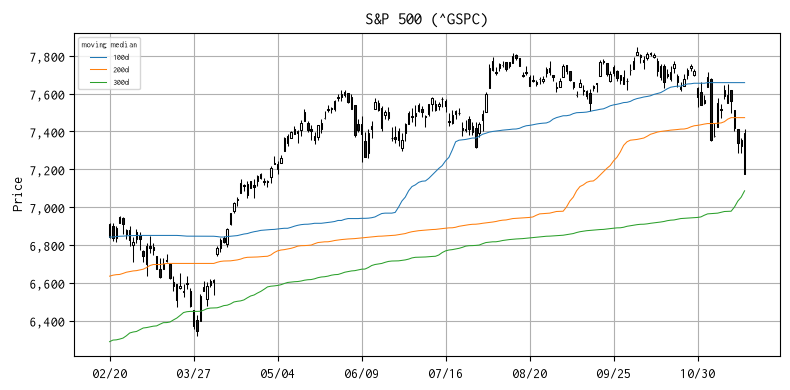

In [5]:
plot_month(symbol1, yticker1, df0, df1)